# Notebook 1: Exploratory Data Analysis (EDA) of LongBench

**Dataset:** `zai-org/LongBench` on Hugging Face (LongBench v1, the 16 English tasks)

**Pipeline stage:** Demo 1, Data Extraction -> Cleaning -> Preprocessing -> Quality Assessment. This notebook covers **extraction, profiling and the first quality assessment**.

**What this notebook answers**
1. What is in the dataset (schema, tasks, sizes)?
2. How long are the contexts, and how many would be cut by a 32K-token cap?
3. What do questions and answers look like for each task type?
4. Are there missing, duplicated or inconsistent records?
5. Is our 800-item dev subset representative of the full set?
6. What is the overall **Data Quality Index** of each task?

## Table of contents
1. Setup and configuration
2. Data extraction (loading all 16 English tasks)
3. Dataset structure and schema
4. Completeness: missing and empty fields
5. Context length analysis (words)
6. Context length analysis (tokens) and truncation impact
7. Question and answer analysis
8. Task-specific analysis
9. Duplicates and shared documents
10. Dev-subset representativeness
11. Data quality assessment and Data Quality Index
12. Summary of findings and export

## 1. Setup and configuration

In [2]:
# Uncomment on the first run only
# %pip install -q pandas numpy matplotlib seaborn scipy huggingface_hub datasets transformers tiktoken

###  ---- 1.1 Imports ----

In [3]:
import os, re, json, hashlib, warnings, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

### ---- 1.2 Global configuration ----

In [4]:
HF_REPO = 'zai-org/LongBench'     # Hugging Face dataset repo
SEED = 42                         # fixed seed for every random operation
DEV_PER_TASK = 50                 # dev subset: 50 items per task (800 in total)
CONTEXT_CAP_TOKENS = 32_000       # team decision: input capped at about 32K tokens
LENGTH_TOLERANCE = 0.10           # allowed gap between the 'length' field and our own word count

OUT_DIR = Path('eda_outputs')
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The 16 English tasks of LongBench v1: task -> (category, official metric)
TASKS = {
    'narrativeqa':          ('Single-Doc QA',   'F1'),
    'qasper':               ('Single-Doc QA',   'F1'),
    'multifieldqa_en':      ('Single-Doc QA',   'F1'),
    'hotpotqa':             ('Multi-Doc QA',    'F1'),
    '2wikimqa':             ('Multi-Doc QA',    'F1'),
    'musique':              ('Multi-Doc QA',    'F1'),
    'gov_report':           ('Summarization',   'ROUGE-L'),
    'qmsum':                ('Summarization',   'ROUGE-L'),
    'multi_news':           ('Summarization',   'ROUGE-L'),
    'trec':                 ('Few-shot',        'Classification score'),
    'triviaqa':             ('Few-shot',        'F1'),
    'samsum':               ('Few-shot',        'ROUGE-L'),
    'passage_count':        ('Synthetic',       'Accuracy'),
    'passage_retrieval_en': ('Synthetic',       'Accuracy'),
    'lcc':                  ('Code',            'Edit similarity'),
    'repobench-p':          ('Code',            'Edit similarity'),
}
print(f'{len(TASKS)} tasks configured')

16 tasks configured


## 2. Data extraction

Each record has these fields: `input` (the question or instruction), `context` (the long text), `answers` (list of reference answers), `length` (word count), `dataset` (task name), `language`, `all_classes` (label set for classification tasks) and `_id`.

### ---- 2.1 Download and cache the raw files (runs once) ----

In [5]:
RAW_DIR = Path('longbench_raw')

def ensure_raw_files():
    # Skip the download if the files are already unpacked
    if RAW_DIR.exists() and any(RAW_DIR.rglob('*.jsonl')):
        return
    from huggingface_hub import hf_hub_download
    zip_path = hf_hub_download(repo_id=HF_REPO, filename='data.zip', repo_type='dataset')
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(RAW_DIR)

def load_task_from_files(task):
    # Read one task's JSONL file line by line (keeps strings and lists exactly as stored)
    matches = list(RAW_DIR.rglob(f'{task}.jsonl'))
    if not matches:
        raise FileNotFoundError(f'{task}.jsonl not found under {RAW_DIR}')
    rows = []
    with open(matches[0], encoding='utf-8') as f:
        for line in f:
            rows.append(json.loads(line))
    return pd.DataFrame(rows)

def load_task_from_hub(task):
    # Fallback route through the datasets library
    from datasets import load_dataset
    ds = load_dataset(HF_REPO, task, split='test', trust_remote_code=True)
    return ds.to_pandas()

def load_task(task):
    try:
        ensure_raw_files()
        return load_task_from_files(task)
    except Exception as err:
        print(f'[{task}] file route failed ({type(err).__name__}: {err}); trying datasets.load_dataset')
        return load_task_from_hub(task)

###  ---- 2.2 Load all 16 tasks into one DataFrame ----

In [6]:
frames = []
for task in TASKS:
    part = load_task(task)
    part['task'] = task          # our own task column, used for every group-by below
    frames.append(part)
    print(f'loaded {task:<22} rows = {len(part)}')

raw = pd.concat(frames, ignore_index=True)
print()
print('Total records loaded:', len(raw))

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


data.zip:   0%|          | 0.00/114M [00:00<?, ?B/s]

loaded narrativeqa            rows = 200
loaded qasper                 rows = 200
loaded multifieldqa_en        rows = 150
loaded hotpotqa               rows = 200
loaded 2wikimqa               rows = 200
loaded musique                rows = 200
loaded gov_report             rows = 200
loaded qmsum                  rows = 200
loaded multi_news             rows = 200
loaded trec                   rows = 200
loaded triviaqa               rows = 200
loaded samsum                 rows = 200
loaded passage_count          rows = 200
loaded passage_retrieval_en   rows = 200
loaded lcc                    rows = 500
loaded repobench-p            rows = 500

Total records loaded: 3750


## 3. Dataset structure and schema

First look: shape, column types, memory footprint and a few example rows

### ---- 3.1 Shape, types, memory ----

In [7]:
print('Rows x columns:', raw.shape)
print()
display(raw.dtypes.astype(str).to_frame('dtype'))
print('Approximate memory (MB):', round(raw.memory_usage(deep=True).sum() / 1e6, 1))

# ---- 3.2 Example rows (context hidden) ----
display(raw.drop(columns=['context']).groupby('task').head(1).reset_index(drop=True))

Rows x columns: (3750, 9)



,dtype
input,object
context,object
answers,object
length,int64
dataset,object
language,object
all_classes,object
_id,object
task,object


Approximate memory (MB): 279.8


,input,answers,length,dataset,language,all_classes,_id,task
0,What is Saltram's living situation?,[He is a guest in the home of the Mulvilles.],22692,narrativeqa,en,None,341d214a2c377691bf20e5a30b8f7979696bd19141ad9c9f,narrativeqa
1,How is the ground truth for fake news established?,[Ground truth is not established in the paper],3141,qasper,en,None,3ac3eef636db11635a21a61804cb28e92c546a5686dd1e12,qasper
2,What is the name of the most active fan club?,[South West Ultras fan club.],819,multifieldqa_en,en,None,c29e95ab6195406aceecf3874186150cb1b8b26db5bcd0e4,multifieldqa_en
3,Which case was brought to court first Miller v. California or Gates v. Collier ?,[Miller v. California],8616,hotpotqa,en,None,fc6267db9ba02bbb251960231bc87251c581110e4e2b5f3f,hotpotqa
4,Where was the wife of Francis I Rákóczi born?,[Ozalj],4696,2wikimqa,en,None,41ac2a4beb0af8f58d01863a62b90692f7c7d74b5e3a58d9,2wikimqa
5,Who plays the wife of the producer of Here Comes the Boom in Grown Ups?,[Maria Bello],11054,musique,en,None,4c114f84ca41284c0845705943adc10b70a4fd3e8d0ca295,musique
6,,[Multiyear procurement (MYP) and block buy contracting (BBC) are special contracting mechanisms ...,8537,gov_report,en,None,4bd6930b3b65caf89aa127d679a80294f31f9cfa7cdab703,gov_report
7,Summarize the discussion about the working design of the remote control.,"[The industrial designer described the product as a portable device with some energy source, an ...",7341,qmsum,en,None,fdd371de2668a6f1e7914fe9a67aef33927ecc392fdc2606,qmsum
8,,[The Occupy LA encampment got a stay of execution this morning—though a few arrests have been re...,2099,multi_news,en,None,e45abfcb82a3c862c0f772e6f461866839955c11ea2f46a8,multi_news
9,Question: Where was the first golf course in the United States ?\nType:,[Other location],3806,trec,en,"[Food, Date, Order, rank, Speed, Disease and medicine, Word with a special property, Abbreviatio...",bb86302b1936b14c09091143ce6e0d4d4013c4789ece0230,trec


### ---- 3.3 Samples per task, with category and metric ----

,n_samples,category,metric
task,,,
narrativeqa,200,Single-Doc QA,F1
qasper,200,Single-Doc QA,F1
multifieldqa_en,150,Single-Doc QA,F1
hotpotqa,200,Multi-Doc QA,F1
2wikimqa,200,Multi-Doc QA,F1
musique,200,Multi-Doc QA,F1
gov_report,200,Summarization,ROUGE-L
qmsum,200,Summarization,ROUGE-L
multi_news,200,Summarization,ROUGE-L


Total English samples: 3750
Team plan expects about 3,750 English items; compare this total with the number above.


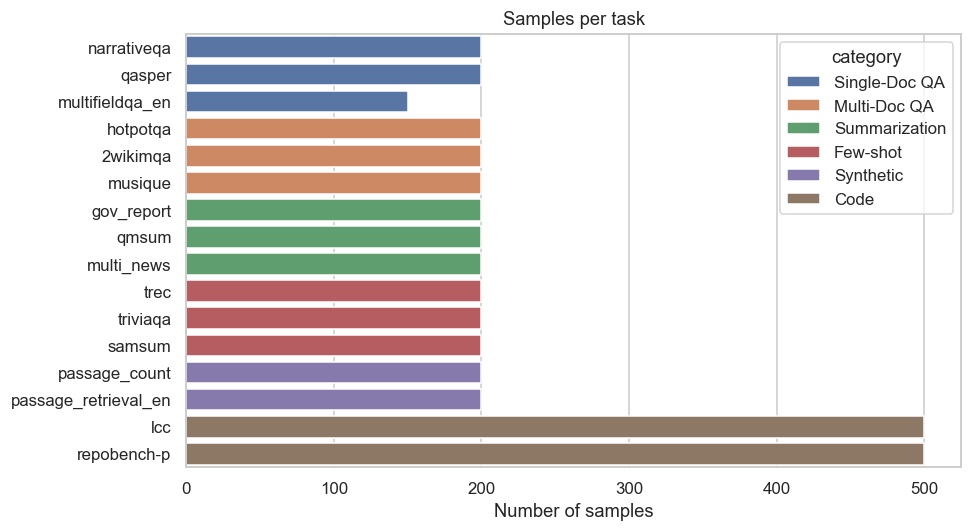

In [8]:
 counts = raw.groupby('task').size().reindex(list(TASKS)).rename('n_samples').to_frame()
counts['category'] = [TASKS[t][0] for t in counts.index]
counts['metric'] = [TASKS[t][1] for t in counts.index]
display(counts)
print('Total English samples:', counts['n_samples'].sum())
print('Team plan expects about 3,750 English items; compare this total with the number above.')

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=counts.reset_index(), x='n_samples', y='task', hue='category', dodge=False, ax=ax)
ax.set_title('Samples per task')
ax.set_xlabel('Number of samples')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG_DIR / '03_samples_per_task.png')
plt.show()

### ---- 3.4 Export sample counts for the project team ----

In [27]:
 # Saving the task-level sample counts so they can be reused

samples_per_task = counts.reset_index()

samples_per_task.to_csv(
    OUT_DIR / "samples_per_task.csv",
    index=False
)

display(samples_per_task)

print("Saved sample-count table to:", OUT_DIR / "samples_per_task.csv")

,task,n_samples,category,metric
0,narrativeqa,200,Single-Doc QA,F1
1,qasper,200,Single-Doc QA,F1
2,multifieldqa_en,150,Single-Doc QA,F1
3,hotpotqa,200,Multi-Doc QA,F1
4,2wikimqa,200,Multi-Doc QA,F1
5,musique,200,Multi-Doc QA,F1
6,gov_report,200,Summarization,ROUGE-L
7,qmsum,200,Summarization,ROUGE-L
8,multi_news,200,Summarization,ROUGE-L
9,trec,200,Few-shot,Classification score


Saved sample-count table to: eda_outputs\samples_per_task.csv


## 4. Completeness: missing and empty fields

A field can be missing (`None`/`NaN`) or present but empty (empty string or empty list). Both break prompt building later. Note that some fields are **empty by design** for certain tasks (for example `all_classes` is only used by classification tasks, and some summarization or code tasks carry no question text in `input`). The heat map below shows the percentage of blank values per task and field so we can tell design from damage.

### ---- 4.1 Blank-value detector ----

,input,context,answers,length,dataset,language,all_classes,_id
task,,,,,,,,
narrativeqa,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
qasper,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
multifieldqa_en,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
hotpotqa,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
2wikimqa,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
musique,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
gov_report,100.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
qmsum,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
multi_news,100.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00


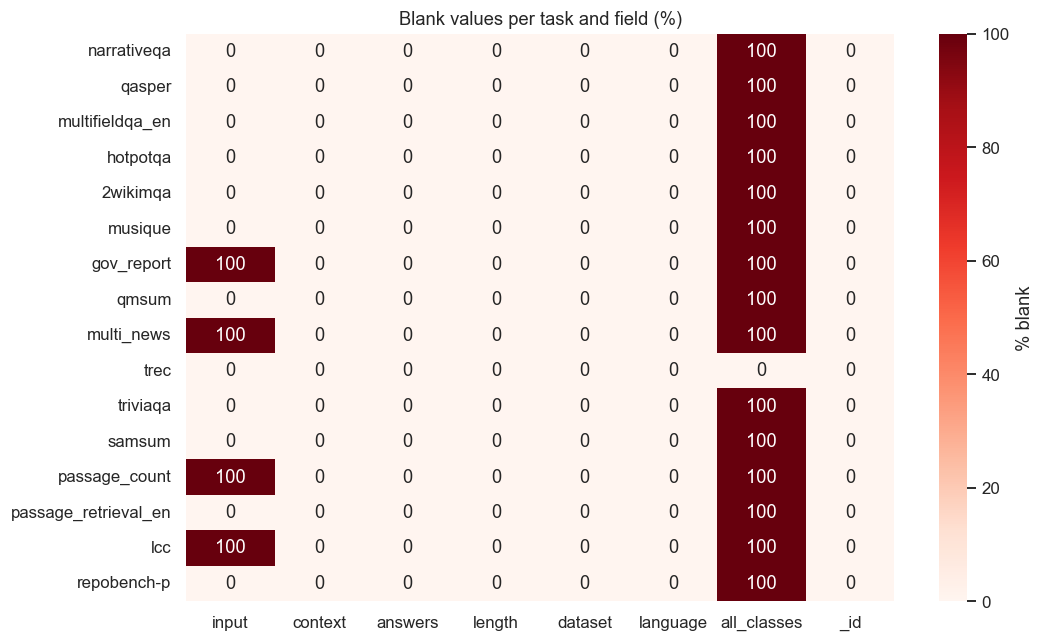

In [9]:
def is_blank(x):
    if x is None:
        return True
    if isinstance(x, float) and np.isnan(x):
        return True
    if isinstance(x, str):
        return x.strip() == ''
    if isinstance(x, (list, tuple, np.ndarray)):
        return len(x) == 0
    return False

FIELDS = ['input', 'context', 'answers', 'length', 'dataset', 'language', 'all_classes', '_id']
FIELDS = [c for c in FIELDS if c in raw.columns]

blank = pd.DataFrame({c: raw[c].map(is_blank) for c in FIELDS})
blank['task'] = raw['task']
blank_rate = blank.groupby('task').mean().reindex(list(TASKS)) * 100

display(blank_rate.round(1))

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(blank_rate, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% blank'}, ax=ax)
ax.set_title('Blank values per task and field (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG_DIR / '04_blank_rate_heatmap.png')
plt.show()

### ---- 4.2 Which fields does each task actually use? ----

In [10]:
# Data-driven rule: a field is 'required' for a task when fewer than 50% of its rows are blank.
# (If most rows are blank, the task simply does not use that field.)
required_fields = {}
for task in TASKS:
    row = blank_rate.loc[task]
    required_fields[task] = [c for c in ['input', 'context', 'answers'] if row[c] < 50]

required_df = pd.Series(required_fields).rename('required_fields').to_frame()
display(required_df)

# Rows where a required field is blank are real defects
defects = 0
for task, fields in required_fields.items():
    mask = (raw['task'] == task)
    for c in fields:
        n = int(blank.loc[mask, c].sum())
        if n:
            print(f'DEFECT: {task}.{c} has {n} blank rows')
            defects += n
print('Total required-field defects:', defects)

,required_fields
narrativeqa,"[input, context, answers]"
qasper,"[input, context, answers]"
multifieldqa_en,"[input, context, answers]"
hotpotqa,"[input, context, answers]"
2wikimqa,"[input, context, answers]"
musique,"[input, context, answers]"
gov_report,"[context, answers]"
qmsum,"[input, context, answers]"
multi_news,"[context, answers]"
trec,"[input, context, answers]"


Total required-field defects: 0


## 5. Context length analysis (words)

The `length` field is the context size (words for English). Long contexts are what fill the KV cache, so this section tells us how much memory pressure each task creates. We also count words ourselves, which is later used to validate the `length` field.

### ---- 5.1 Our own word counts ----

In [11]:
raw['context_words'] = raw['context'].str.split().str.len()
raw['input_words'] = raw['input'].str.split().str.len().fillna(0)

# ---- 5.2 Descriptive statistics of the official 'length' field, per task ----
length_stats = (raw.groupby('task')['length']
                   .describe(percentiles=[.05, .25, .5, .75, .95])
                   .reindex(list(TASKS)))
display(length_stats)

,count,mean,std,min,5%,25%,50%,75%,95%,max
task,,,,,,,,,,
narrativeqa,200.00,"18,404.94","8,975.97","5,397.00","6,592.00","10,012.50","17,499.50","25,090.00","31,695.20","36,418.00"
qasper,200.00,"3,618.70","1,879.86","1,440.00","1,686.55","2,423.75","3,417.50","4,268.75","6,391.00","14,660.00"
multifieldqa_en,150.00,"4,558.70","2,472.90",505.00,855.65,"2,294.25","4,995.50","6,418.00","8,506.50","10,337.00"
hotpotqa,200.00,"9,149.22","2,849.02","1,078.00","3,497.00","7,661.00","10,104.00","11,460.75","12,151.65","12,697.00"
2wikimqa,200.00,"4,885.31","2,541.43",535.00,"1,666.60","3,289.00","4,209.50","5,881.25","10,458.10","11,950.00"
musique,200.00,"11,017.66","1,559.67","3,440.00","8,291.90","10,766.75","11,386.00","11,725.00","12,329.70","17,355.00"
gov_report,200.00,"8,169.36","5,238.75","1,743.00","2,560.05","4,947.00","7,022.50","9,926.25","15,677.00","40,508.00"
qmsum,200.00,"10,545.94","5,042.99","1,789.00","3,980.00","6,954.75","10,199.50","12,785.25","20,281.05","24,585.00"
multi_news,200.00,"2,113.49","1,554.51",258.00,705.75,"1,209.75","1,653.00","2,522.25","4,781.65","10,933.00"


### ---- 5.3 Box plot (log scale) and per-task histograms ----

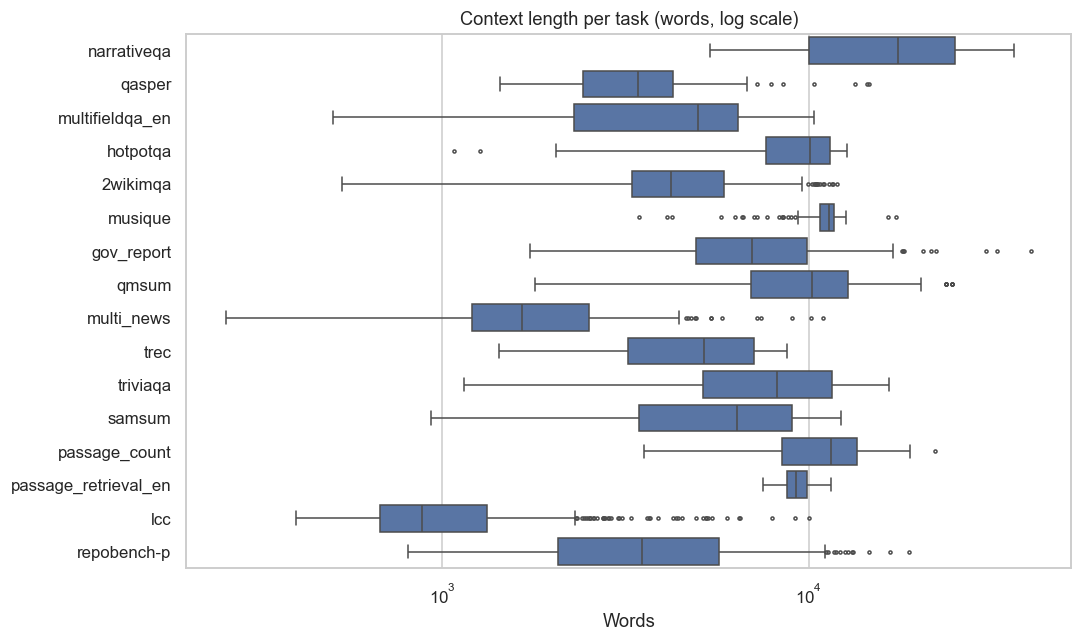

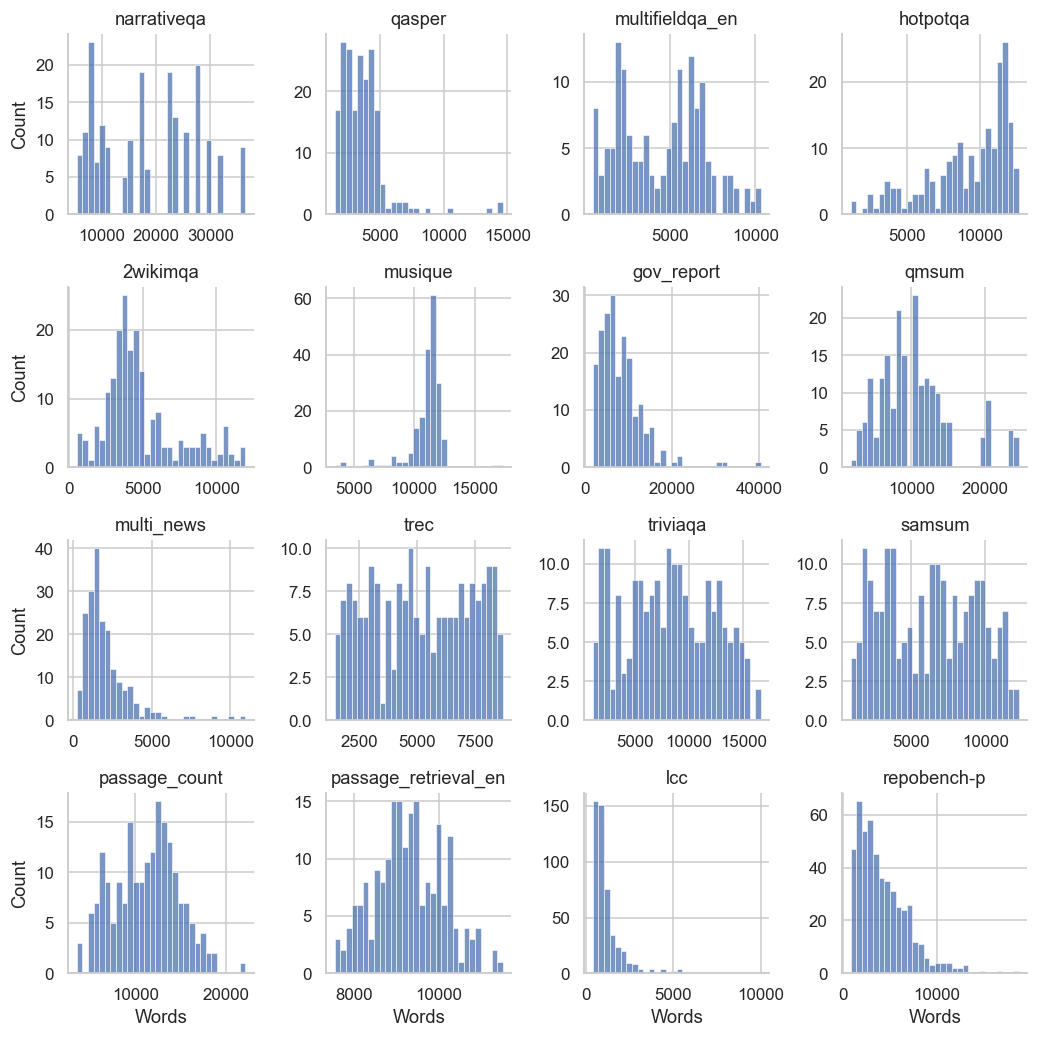

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=raw, x='length', y='task', order=list(TASKS), ax=ax, fliersize=2)
ax.set_xscale('log')
ax.set_title('Context length per task (words, log scale)')
ax.set_xlabel('Words')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG_DIR / '05_length_boxplot.png')
plt.show()

g = sns.FacetGrid(raw, col='task', col_order=list(TASKS), col_wrap=4, sharex=False, sharey=False, height=2.4)
g.map_dataframe(sns.histplot, x='length', bins=30)
g.set_titles('{col_name}')
g.set_axis_labels('Words', 'Count')
plt.tight_layout()
plt.savefig(FIG_DIR / '05_length_histograms.png')
plt.show()

## 6. Context length analysis (tokens) and truncation impact

Models read **tokens**, not words, and our study caps the input at about 32K tokens (middle truncation, as LongBench does). To estimate how many samples get truncated, we:
1. tokenize a small random sample per task,
2. compute each task's tokens-per-word ratio,
3. apply that ratio to every record's word count.

The tokenizer is chosen automatically: the Llama-3.1 tokenizer if you have Hugging Face access to it, otherwise `tiktoken` (an approximation), otherwise a rough words x 1.3 rule.

###  ---- 6.1 Choosing the best available tokenizer ----

In [13]:
def get_token_counter():
    try:
        from transformers import AutoTokenizer
        tok = AutoTokenizer.from_pretrained('meta-llama/Llama-3.1-8B-Instruct')
        return 'Llama-3.1 tokenizer', (lambda t: len(tok.encode(t, add_special_tokens=False)))
    except Exception as err:
        print('Llama tokenizer unavailable:', type(err).__name__)
    try:
        import tiktoken
        enc = tiktoken.get_encoding('cl100k_base')
        return 'tiktoken cl100k_base (approximation)', (lambda t: len(enc.encode(t, disallowed_special=())))
    except Exception as err:
        print('tiktoken unavailable:', type(err).__name__)
    return 'words x 1.3 (rough rule)', (lambda t: int(len(t.split()) * 1.3))

tokenizer_name, count_tokens = get_token_counter()
print('Token counting method:', tokenizer_name)

Disabling PyTorch because PyTorch >= 2.1 is required but found 2.0.1


Llama tokenizer unavailable: OSError
Token counting method: tiktoken cl100k_base (approximation)


### ---- 6.2 Tokens-per-word ratio from a small sample per task ----

In [14]:
TOK_SAMPLE_PER_TASK = 30

sample = (raw.groupby('task', group_keys=False)
             .apply(lambda g: g.sample(min(len(g), TOK_SAMPLE_PER_TASK), random_state=SEED))
             .copy())
sample['prompt_text'] = sample['context'] + ' ' + sample['input'].fillna('')
sample['tokens'] = sample['prompt_text'].map(count_tokens)
sample['words'] = sample['prompt_text'].str.split().str.len()

ratio = (sample.groupby('task')['tokens'].sum() / sample.groupby('task')['words'].sum()).rename('tokens_per_word')
display(ratio.reindex(list(TASKS)).to_frame())

# ---- 6.3 Estimated prompt tokens for every record ----
raw['est_tokens'] = (raw['context_words'] + raw['input_words']) * raw['task'].map(ratio)
display(raw.groupby('task')['est_tokens'].describe().reindex(list(TASKS)))

,tokens_per_word
task,
narrativeqa,1.65
qasper,1.39
multifieldqa_en,1.53
hotpotqa,1.39
2wikimqa,1.44
musique,1.40
gov_report,1.25
qmsum,1.29
multi_news,1.37


,count,mean,std,min,25%,50%,75%,max
task,,,,,,,,
narrativeqa,200.00,"30,325.01","14,790.12","8,891.24","16,496.41","28,833.08","41,340.29","60,005.96"
qasper,200.00,"5,010.67","2,610.90","1,993.37","3,350.52","4,709.77","5,919.68","20,344.85"
multifieldqa_en,150.00,"6,941.46","3,771.60",769.07,"3,495.53","7,610.60","9,762.16","15,770.53"
hotpotqa,200.00,"12,716.97","3,960.43","1,497.14","10,648.19","14,044.22","15,930.24","17,648.75"
2wikimqa,200.00,"7,053.40","3,670.06",771.14,"4,748.17","6,077.46","8,491.62","17,255.45"
musique,200.00,"15,689.40","1,954.20","5,352.65","15,464.61","16,208.38","16,687.67","17,762.40"
gov_report,200.00,"10,200.87","6,542.30","2,175.46","6,176.70","8,768.64","12,394.92","50,586.23"
qmsum,200.00,"13,616.81","6,512.08","2,308.87","8,979.46","13,169.45","16,508.46","31,745.62"
multi_news,200.00,"2,596.95","2,086.39",156.39,"1,407.55","2,015.29","3,162.87","14,155.07"


### ---- 6.4 Share of samples above different caps (% truncated) ----

,> 4K tokens,> 8K tokens,> 16K tokens,> 32K tokens
task,,,,
narrativeqa,100.00,100.00,75.50,45.00
qasper,61.50,7.00,1.50,0.00
multifieldqa_en,66.70,46.70,0.00,0.00
hotpotqa,96.50,85.50,24.50,0.00
2wikimqa,86.00,28.50,2.00,0.00
musique,100.00,98.50,60.00,0.00
gov_report,89.00,55.00,12.50,1.50
qmsum,99.50,80.00,27.50,0.00
multi_news,15.50,2.50,0.00,0.00


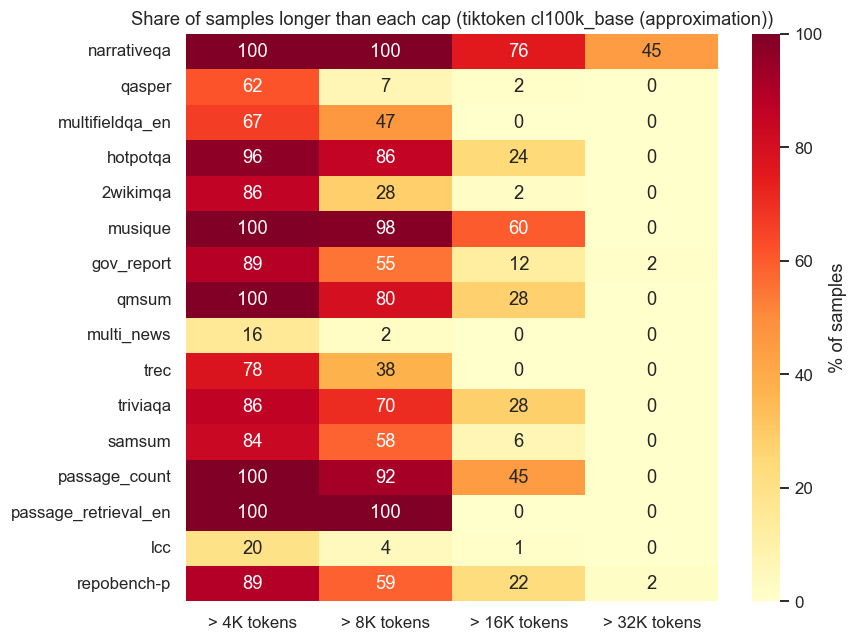

Overall share above the 32,000-token cap: 2.7%


In [15]:
CAPS = [4_000, 8_000, 16_000, 32_000]
trunc = pd.DataFrame({
    f'> {c // 1000}K tokens': raw.groupby('task')['est_tokens'].apply(lambda s, c=c: (s > c).mean() * 100)
    for c in CAPS
}).reindex(list(TASKS))
display(trunc.round(1))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(trunc, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': '% of samples'}, ax=ax)
ax.set_title(f'Share of samples longer than each cap ({tokenizer_name})')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG_DIR / '06_truncation_heatmap.png')
plt.show()

overall = (raw['est_tokens'] > CONTEXT_CAP_TOKENS).mean() * 100
print(f'Overall share above the {CONTEXT_CAP_TOKENS:,}-token cap: {overall:.1f}%')

## 7. Question and answer analysis

Question length, number of reference answers and answer length drive three things: prompt size, how generation length should be set, and which metric is meaningful. Short extractive answers (F1) behave very differently under compression than long summaries (ROUGE-L).

### ---- 7.1 Answer-level features ----

In [16]:
def n_items(a):
    return len(a) if hasattr(a, '__len__') and not isinstance(a, str) else 0

def mean_answer_words(a):
    if hasattr(a, '__len__') and not isinstance(a, str) and len(a) > 0:
        return float(np.mean([len(str(x).split()) for x in a]))
    return np.nan

raw['n_answers'] = raw['answers'].map(n_items)
raw['answer_words'] = raw['answers'].map(mean_answer_words)

qa_stats = raw.groupby('task').agg(
    question_words_mean=('input_words', 'mean'),
    question_words_max=('input_words', 'max'),
    answers_per_item_mean=('n_answers', 'mean'),
    answers_per_item_max=('n_answers', 'max'),
    answer_words_median=('answer_words', 'median'),
    answer_words_p95=('answer_words', lambda s: s.quantile(0.95)),
    answer_words_max=('answer_words', 'max'),
).reindex(list(TASKS))
display(qa_stats)

,question_words_mean,question_words_max,answers_per_item_mean,answers_per_item_max,answer_words_median,answer_words_p95,answer_words_max
task,,,,,,,
narrativeqa,8.70,22,1.00,1,4.00,11.00,28.00
qasper,7.81,24,1.75,3,7.75,36.27,91.00
multifieldqa_en,10.35,22,1.00,1,9.00,19.00,37.00
hotpotqa,15.24,38,1.00,1,2.00,6.00,15.00
2wikimqa,11.71,23,1.00,1,2.00,5.00,14.00
musique,15.62,39,1.37,5,2.00,5.00,10.00
gov_report,0.00,0,1.00,1,575.00,744.80,"1,147.00"
qmsum,11.62,30,1.00,1,65.50,127.20,177.00
multi_news,0.00,0,1.00,1,219.50,318.25,615.00


### ---- 7.2 Visualise answer length and question length ----

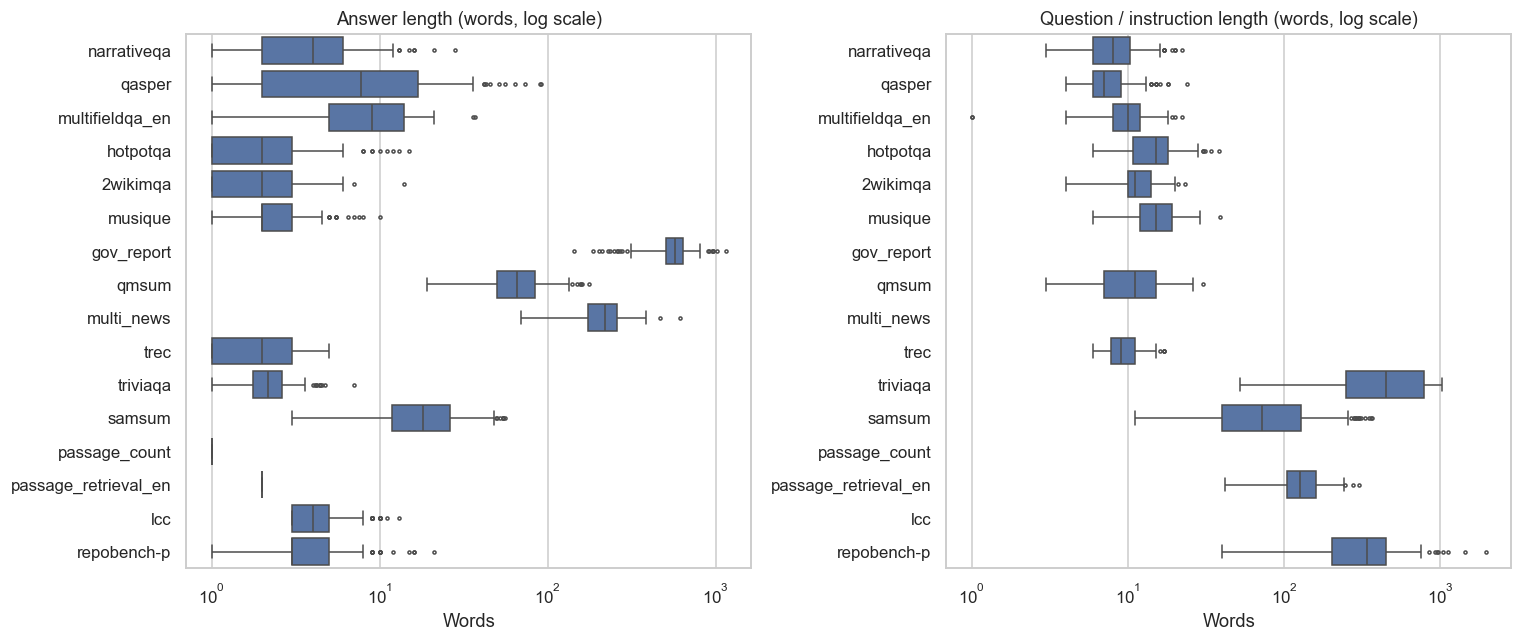

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=raw, x='answer_words', y='task', order=list(TASKS), ax=axes[0], fliersize=2)
axes[0].set_xscale('log')
axes[0].set_title('Answer length (words, log scale)')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('')

sns.boxplot(data=raw[raw['input_words'] > 0], x='input_words', y='task', order=list(TASKS), ax=axes[1], fliersize=2)
axes[1].set_xscale('log')
axes[1].set_title('Question / instruction length (words, log scale)')
axes[1].set_xlabel('Words')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig(FIG_DIR / '07_answer_question_length.png')
plt.show()

## 8. Task-specific analysis

Each task family has its own structure worth checking: label balance for classification, answer ranges for the synthetic tasks, code size for code completion, question types for QA and compression ratios for summarization.

### ---- 8.1 Classification (trec): label distribution ----

,count
Definition of something,47
Individual,24
Other location,22
Date,21
City,9
"Distance, linear measure",9
Other entity,5
Color,4
Currency name,4
Group or organization of person,4


Number of candidate classes listed in all_classes: 50


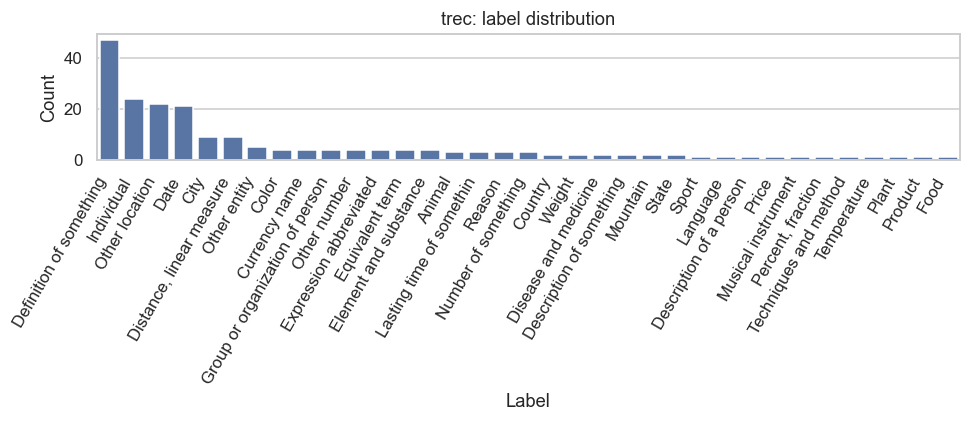

In [18]:
trec = raw[raw['task'] == 'trec'].copy()
trec['label'] = trec['answers'].map(lambda a: a[0] if n_items(a) > 0 else None)
label_counts = trec['label'].value_counts()
display(label_counts.to_frame('count'))

classes = trec['all_classes'].iloc[0] if 'all_classes' in trec.columns else None
if classes is not None and hasattr(classes, '__len__'):
    print('Number of candidate classes listed in all_classes:', len(classes))

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=label_counts.index.astype(str), y=label_counts.values, ax=ax)
ax.set_title('trec: label distribution')
ax.set_xlabel('Label')
ax.set_ylabel('Count')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig(FIG_DIR / '08_trec_labels.png')
plt.show()

### ---- 8.2 Synthetic tasks: passage_count and passage_retrieval_en ----

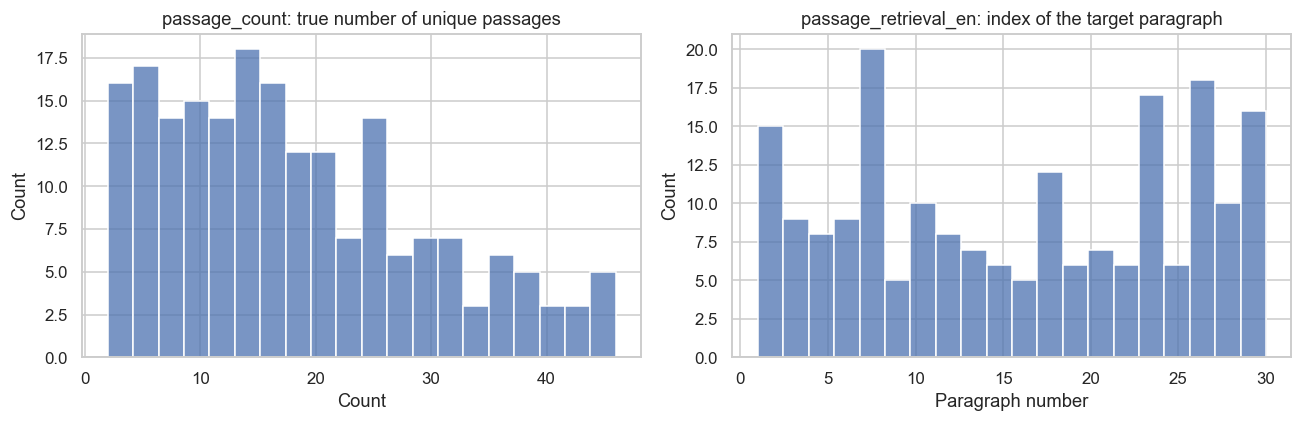

passage_count answers parsed: 200 of 200
passage_retrieval_en answers parsed: 200 of 200


In [19]:
def first_number(a):
    if n_items(a) == 0:
        return np.nan
    m = re.search(r'(\d+)', str(a[0]))
    return float(m.group(1)) if m else np.nan

pc = raw[raw['task'] == 'passage_count'].copy()
pc['target'] = pc['answers'].map(first_number)

pr = raw[raw['task'] == 'passage_retrieval_en'].copy()
pr['target'] = pr['answers'].map(first_number)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pc['target'].dropna(), bins=20, ax=axes[0])
axes[0].set_title('passage_count: true number of unique passages')
axes[0].set_xlabel('Count')
sns.histplot(pr['target'].dropna(), bins=20, ax=axes[1])
axes[1].set_title('passage_retrieval_en: index of the target paragraph')
axes[1].set_xlabel('Paragraph number')
plt.tight_layout()
plt.savefig(FIG_DIR / '08_synthetic_targets.png')
plt.show()

print('passage_count answers parsed:', int(pc['target'].notna().sum()), 'of', len(pc))
print('passage_retrieval_en answers parsed:', int(pr['target'].notna().sum()), 'of', len(pr))

### ---- 8.3 Code tasks: size of the code context ----

task                      lcc  repobench-p
context_lines count    500.00       500.00
              mean     328.19     1,281.91
              std      261.48       864.51
              min      149.00        93.00
              25%      194.00       609.75
              50%      236.50     1,071.00
              75%      342.00     1,723.00
              max    2,273.00     5,140.00
answer_lines  count    500.00       500.00
              mean       1.00         1.00
              std        0.00         0.00
              min        1.00         1.00
              25%        1.00         1.00
              50%        1.00         1.00
              75%        1.00         1.00
              max        1.00         1.00
length        count    500.00       500.00
              mean   1,235.28     4,205.93
              std    1,085.73     2,698.30
              min      399.00       810.00
              25%      677.00     2,078.00
              50%      883.00     3,503.50
              75%    1,329.00     5,701.25
              max   10,029.00    18,754.00

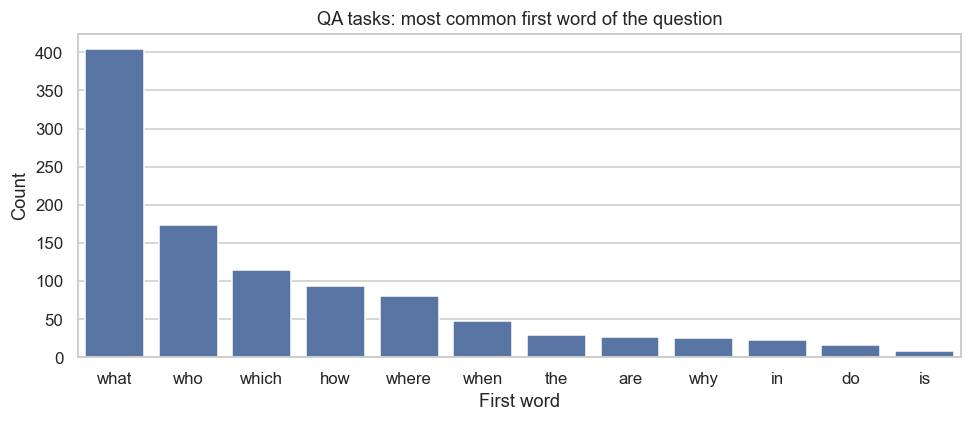

In [20]:
code = raw[raw['task'].isin(['lcc', 'repobench-p'])].copy()
code['context_lines'] = code['context'].str.count(chr(10)) + 1
code['answer_lines'] = code['answers'].map(lambda a: str(a[0]).count(chr(10)) + 1 if n_items(a) > 0 else np.nan)

display(code.groupby('task')[['context_lines', 'answer_lines', 'length']].describe().T)

# ---- 8.4 QA tasks: what kinds of questions are asked (first word) ----
qa_tasks = ['narrativeqa', 'qasper', 'multifieldqa_en', 'hotpotqa', '2wikimqa', 'musique']
qa = raw[raw['task'].isin(qa_tasks)].copy()
qa['first_word'] = qa['input'].str.strip().str.split().str[0].str.lower()
top_words = qa['first_word'].value_counts().head(12)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=top_words.index, y=top_words.values, ax=ax)
ax.set_title('QA tasks: most common first word of the question')
ax.set_xlabel('First word')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig(FIG_DIR / '08_qa_first_words.png')
plt.show()

### ---- 8.5 Summarization tasks: how much is the document compressed? ----

task                     gov_report  multi_news     qmsum
context_words     count      200.00      200.00    200.00
                  mean     8,168.36    1,892.98 10,533.33
                  std      5,238.75    1,520.83  5,043.49
                  min      1,742.00      114.00  1,781.00
                  25%      4,946.00    1,026.00  6,947.00
                  50%      7,021.50    1,469.00 10,191.00
                  75%      9,925.25    2,305.50 12,777.00
                  max     40,507.00   10,318.00 24,573.00
answer_words      count      200.00      200.00    200.00
                  mean       565.87      220.50     69.43
                  std        146.53       69.44     29.06
                  min        143.00       69.00     19.00
                  25%        504.50      173.00     49.75
                  50%        575.00      219.50     65.50
                  75%        641.00      258.00     84.00
                  max      1,147.00      615.00    177.00
compression_ratio count      200.00      200.00    200.00
                  mean        14.77        8.69    182.97
                  std          9.26        6.30    132.70
                  min          3.27        0.54     17.81
                  25%          9.14        5.06     98.92
                  50%         12.95        6.89    135.37
                  75%         17.66       11.39    233.55
                  max         67.40       50.98    679.31

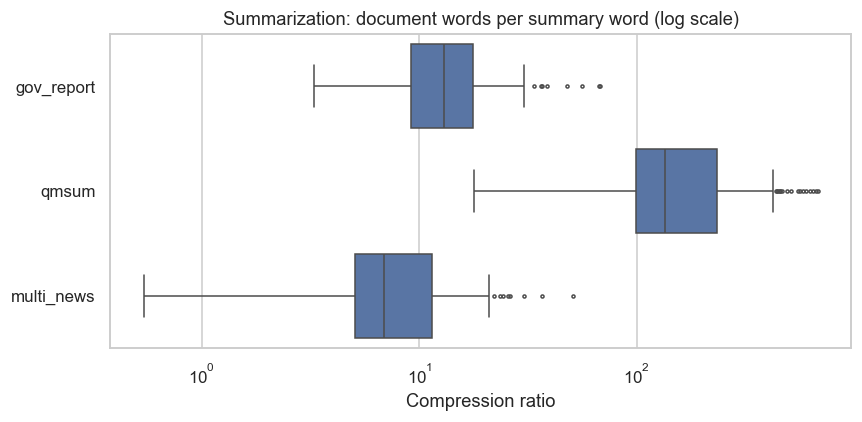

In [21]:
summ = raw[raw['task'].isin(['gov_report', 'qmsum', 'multi_news'])].copy()
summ['compression_ratio'] = summ['context_words'] / summ['answer_words']
display(summ.groupby('task')[['context_words', 'answer_words', 'compression_ratio']].describe().T)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=summ, x='compression_ratio', y='task', ax=ax, fliersize=2)
ax.set_xscale('log')
ax.set_title('Summarization: document words per summary word (log scale)')
ax.set_xlabel('Compression ratio')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG_DIR / '08_summarization_compression.png')
plt.show()

## 9. Duplicates and shared documents

Two different things are checked here:
- **True duplicates** (same id, or same document and same question): these would count twice in the scores and must be removed in cleaning.
- **Shared documents** (the same document with different questions): these are not defects. They are useful for the **multi-turn reuse test (R10)**, which needs a second question about a document that has already been compressed.

### ---- 9.1 Fingerprint each document ----

In [22]:
raw['context_hash'] = raw['context'].map(lambda s: hashlib.md5(str(s).encode('utf-8')).hexdigest())

# ---- 9.2 True duplicates ----
dup_id = int(raw['_id'].duplicated().sum())
dup_pair = int(raw.duplicated(subset=['task', 'context_hash', 'input']).sum())
print('Duplicate _id values              :', dup_id)
print('Duplicate (document, question)    :', dup_pair)

# ---- 9.3 Shared documents (candidates for multi-turn second questions) ----
docs = raw.groupby(['task', 'context_hash']).size().rename('n_questions').reset_index()
shared = docs.groupby('task')['n_questions'].agg(
    unique_documents='count',
    max_questions_per_document='max',
    documents_with_2plus_questions=lambda s: int((s >= 2).sum()),
).reindex(list(TASKS))
display(shared)
print('Tasks with at least one shared document:', int((shared['documents_with_2plus_questions'] > 0).sum()))

Duplicate _id values              : 0
Duplicate (document, question)    : 19


,unique_documents,max_questions_per_document,documents_with_2plus_questions
task,,,
narrativeqa,20,19,20
qasper,148,3,43
multifieldqa_en,112,4,29
hotpotqa,200,1,0
2wikimqa,200,1,0
musique,200,1,0
gov_report,200,1,0
qmsum,35,11,34
multi_news,200,1,0


Tasks with at least one shared document: 4


## 10. Dev-subset representativeness

During development the team uses a fixed stratified sample of **50 items per task (800 items)**. This section builds a seeded preview of that sample and checks with a **Kolmogorov-Smirnov test** that its length distribution matches the full task (a large p-value means no evidence of a difference).

### ---- 10.1 Seeded stratified sample ----

In [23]:
dev = (raw.groupby('task', group_keys=False)
          .apply(lambda g: g.sample(min(len(g), DEV_PER_TASK), random_state=SEED)))
print('Dev subset size:', len(dev))

# ---- 10.2 Compare dev vs full per task ----
rows = []
for task in TASKS:
    full_len = raw.loc[raw['task'] == task, 'length']
    dev_len = dev.loc[dev['task'] == task, 'length']
    stat, p = ks_2samp(full_len, dev_len)
    rows.append({
        'task': task,
        'n_full': len(full_len),
        'n_dev': len(dev_len),
        'mean_len_full': full_len.mean(),
        'mean_len_dev': dev_len.mean(),
        'ks_statistic': stat,
        'ks_p_value': p,
        'representative': p > 0.05,
    })
dev_check = pd.DataFrame(rows).set_index('task')
display(dev_check)
print('Tasks where the dev subset differs significantly (p <= 0.05):',
      dev_check.index[~dev_check['representative']].tolist())

Dev subset size: 800


,n_full,n_dev,mean_len_full,mean_len_dev,ks_statistic,ks_p_value,representative
task,,,,,,,
narrativeqa,200,50,"18,404.94","17,799.70",0.07,0.99,True
qasper,200,50,"3,618.70","3,624.90",0.07,0.99,True
multifieldqa_en,150,50,"4,558.70","4,831.50",0.11,0.77,True
hotpotqa,200,50,"9,149.22","9,462.24",0.10,0.84,True
2wikimqa,200,50,"4,885.31","5,126.48",0.07,0.99,True
musique,200,50,"11,017.66","10,758.46",0.12,0.59,True
gov_report,200,50,"8,169.36","9,609.44",0.14,0.39,True
qmsum,200,50,"10,545.94","10,074.74",0.10,0.80,True
multi_news,200,50,"2,113.49","2,247.22",0.12,0.64,True


Tasks where the dev subset differs significantly (p <= 0.05): []


## 11. Data quality assessment and the Data Quality Index

**Data quality assessment** means measuring, with numbers, whether the data is fit for the job it has to do. Instead of saying that the data looks fine, each quality dimension gets a score between 0 and 1 (the share of records that pass its checks).

| Dimension | Question it answers | Check used here |
| --- | --- | --- |
| Completeness | Is everything we need present? | Required fields are not blank |
| Validity | Are the values correct and well-formed? | `length` matches our own word count within the tolerance; answers are text; no broken characters |
| Uniqueness | Is each record counted once? | No duplicate `_id`, no duplicate document and question pair |
| Consistency | Do records agree with the schema and each other? | `language` is English and `dataset` matches the task |
| Fitness for use | Can our setup use it? | Estimated prompt fits within the token cap |

The **Data Quality Index (DQI)** combines the dimension scores into one number from 0 to 100 using weights:

`DQI = 100 x (w1 x Completeness + w2 x Validity + w3 x Uniqueness + w4 x Consistency + w5 x Fitness)`

The weights are set in the next cell and can be changed. Fitness is not a defect of the data itself, so a low fitness score means many samples need truncation, not that the data is wrong. Notebook 2 recomputes the index **after cleaning** to show the before and after improvement.

### ---- 11.1 Row-level quality flags (True = record passes the check) ----

In [28]:
QUALITY_WEIGHTS = {
    'completeness': 0.30,
    'validity':     0.25,
    'uniqueness':   0.15,
    'consistency':  0.15,
    'fitness':      0.15,
}
assert abs(sum(QUALITY_WEIGHTS.values()) - 1.0) < 1e-9, 'weights must sum to 1'

q = pd.DataFrame(index=raw.index)
q['task'] = raw['task']

# Completeness: every field the task uses is present
def complete_row(i):
    return not any(blank.loc[i, c] for c in required_fields[raw.at[i, 'task']])
q['completeness'] = [complete_row(i) for i in raw.index]

# Validity: length field close to our own count, answers are text, no replacement characters
bad_char = chr(0xFFFD)
length_gap = (raw['length'] - raw['context_words']).abs() / raw['context_words'].clip(lower=1)
length_ok = length_gap <= LENGTH_TOLERANCE
answers_text_ok = raw['answers'].map(lambda a: n_items(a) > 0 and all(isinstance(x, str) and x.strip() != '' for x in a))
no_bad_chars = ~raw['context'].str.contains(bad_char, regex=False)
q['validity'] = length_ok & answers_text_ok & no_bad_chars

# Uniqueness
q['uniqueness'] = ~(raw['_id'].duplicated(keep='first') | raw.duplicated(subset=['task', 'context_hash', 'input'], keep='first'))

# Consistency
# Consistency:
# - Every record should be in English.
# - The dataset metadata should be present.
# - The task should belong to the configured LongBench task list.
#
# We do not directly compare dataset and task names because
# some LongBench task metadata names differ from the local task keys.

language_ok = raw['language'].astype(str).str.lower().eq('en')

dataset_present = raw['dataset'].map(
    lambda x: isinstance(x, str) and x.strip() != ''
)

task_known = raw['task'].isin(TASKS)

q['consistency'] = language_ok & dataset_present & task_known

# Fitness for use
q['fitness'] = raw['est_tokens'] <= CONTEXT_CAP_TOKENS

# ---- 11.2 Scorecard per task ----
dims = list(QUALITY_WEIGHTS)
scorecard = q.groupby('task')[dims].mean().reindex(list(TASKS))
scorecard['DQI'] = 100 * sum(w * scorecard[d] for d, w in QUALITY_WEIGHTS.items())

def grade(x):
    if x >= 95: return 'Excellent'
    if x >= 85: return 'Good'
    return 'Needs work'
scorecard['grade'] = scorecard['DQI'].map(grade)

display(scorecard.round(3))

overall_dqi = 100 * sum(w * q[d].mean() for d, w in QUALITY_WEIGHTS.items())
print(f'Overall Data Quality Index (all tasks): {overall_dqi:.1f} / 100')

,completeness,validity,uniqueness,consistency,fitness,DQI,grade
task,,,,,,,
narrativeqa,1.00,1.00,0.91,1.00,0.55,91.90,Good
qasper,1.00,1.00,1.00,1.00,1.00,100.00,Excellent
multifieldqa_en,1.00,0.99,0.99,1.00,1.00,99.73,Excellent
hotpotqa,1.00,0.99,1.00,1.00,1.00,99.88,Excellent
2wikimqa,1.00,1.00,1.00,1.00,1.00,100.00,Excellent
musique,1.00,0.99,1.00,1.00,1.00,99.75,Excellent
gov_report,1.00,1.00,1.00,1.00,0.98,99.78,Excellent
qmsum,1.00,1.00,1.00,1.00,1.00,100.00,Excellent
multi_news,1.00,0.26,1.00,1.00,1.00,81.38,Needs work


Overall Data Quality Index (all tasks): 92.4 / 100


### ---- 11.3 Visualise the scorecard ----

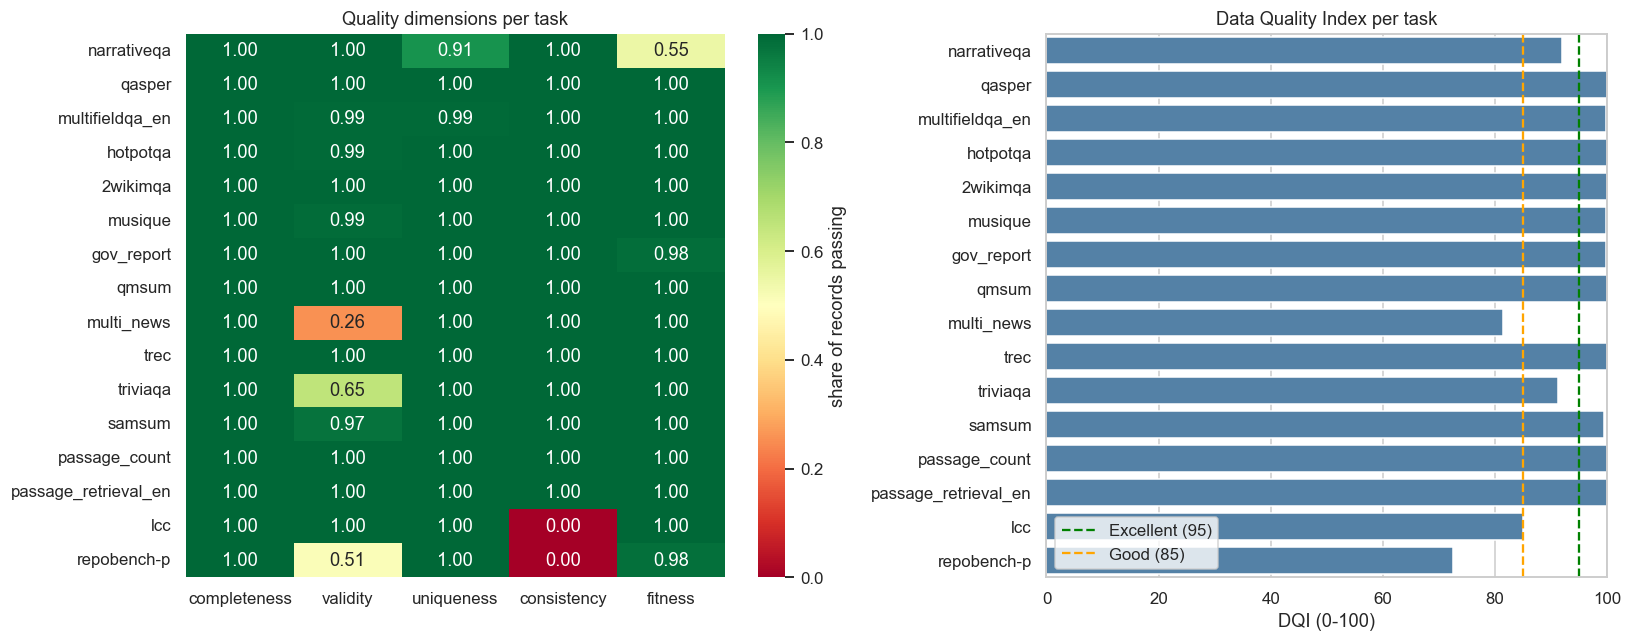

Records failing two or more checks: 257


,task,completeness,validity,uniqueness,consistency,fitness,n_failed,_id
17,narrativeqa,True,True,False,True,False,2,7efd1cc4cce3770765ac6c7304b68cfe28c83aec18c01577
47,narrativeqa,True,True,False,True,False,2,cf6cd2d8526658bac5ee4a39bc0237021c54eec652d27d1b
110,narrativeqa,True,True,False,True,False,2,1cf24ba18f6900bb1f182594f614a8da725a8467d6255e08
118,narrativeqa,True,True,False,True,False,2,979294831f2e204dd0340f8017a76400d0e67bf7feb92629
173,narrativeqa,True,True,False,True,False,2,fbeb825de92309788269da33aa6bd189c7b1d46b997746f4
3256,repobench-p,True,False,True,False,True,2,47573702c5f1ad33b86b8645ddc49617af39e584b4303008
3258,repobench-p,True,False,True,False,True,2,d60990d706853cd274c7ff6b8b766fcccca25dc8de5ae49c
3261,repobench-p,True,False,True,False,True,2,0697cb04cdcd9172485f3f0398a5d0f1a9a8061972ff6197
3262,repobench-p,True,False,True,False,True,2,b3e2346d898f5d979d88e1ef30c8d97a9e53c92308800882
3263,repobench-p,True,False,True,False,True,2,31be7d5ae81230c8f97a65a4360e143cd828be77c08f3863


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.2, 1]})

sns.heatmap(scorecard[dims], annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            cbar_kws={'label': 'share of records passing'}, ax=axes[0])
axes[0].set_title('Quality dimensions per task')
axes[0].set_ylabel('')

sns.barplot(x=scorecard['DQI'], y=scorecard.index, ax=axes[1], color='steelblue')
axes[1].axvline(95, color='green', linestyle='--', label='Excellent (95)')
axes[1].axvline(85, color='orange', linestyle='--', label='Good (85)')
axes[1].set_xlim(0, 100)
axes[1].set_title('Data Quality Index per task')
axes[1].set_xlabel('DQI (0-100)')
axes[1].set_ylabel('')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig(FIG_DIR / '11_quality_scorecard.png')
plt.show()

# ---- 11.4 Records that fail the most checks (first candidates for cleaning) ----
q['n_failed'] = (~q[dims]).sum(axis=1)
worst = q[q['n_failed'] >= 2].join(raw[['_id']])
print('Records failing two or more checks:', len(worst))
display(worst.head(15))

### Interpretation and limitations

The Data Quality Index is a project-defined diagnostic score, not an official LongBench metric. Some lower task-level scores may reflect differences in task-specific schemas rather than genuinely poor data quality. For example, code-completion tasks may use different metadata conventions, and some tasks may contain multiple valid reference answers.

The token-length analysis is an estimate because the exact Llama-3.1 tokenizer was unavailable during EDA. The notebook therefore used the `tiktoken cl100k_base` tokenizer and estimated tokens for the full dataset using task-level tokens-per-word ratios. Exact token counts will be calculated during preprocessing using the tokenizer of the final evaluation model.

The fitness score indicates whether an example is likely to exceed the project’s context limit. It represents operational suitability for the KV-cache experiments, not an error in the original dataset.

## 12. Summary of findings and export

The next cell prints a short, automatically generated findings list from the numbers above, so the text always matches the data.

### ---- 12.1 Auto-generated findings ----

In [26]:
longest = raw.groupby('task')['length'].median().idxmax()
shortest = raw.groupby('task')['length'].median().idxmin()
most_trunc = trunc[f'> {CONTEXT_CAP_TOKENS // 1000}K tokens'].idxmax()
worst_task = scorecard['DQI'].idxmin()
best_task = scorecard['DQI'].idxmax()

lines = [
    f'1. The dataset has {len(raw):,} English records across {raw["task"].nunique()} tasks and {raw["task"].map(lambda t: TASKS[t][0]).nunique()} categories.',
    f'2. Median context length ranges from {int(raw.groupby("task")["length"].median().min()):,} words ({shortest}) to {int(raw.groupby("task")["length"].median().max()):,} words ({longest}).',
    f'3. About {overall:.1f}% of all samples exceed the {CONTEXT_CAP_TOKENS:,}-token cap (estimated with {tokenizer_name}); the most affected task is {most_trunc}.',
    f'4. Required-field defects found: {defects}. Duplicate ids: {dup_id}. Duplicate document-question pairs: {dup_pair}.',
    f'5. {int((shared["documents_with_2plus_questions"] > 0).sum())} tasks contain documents with two or more questions, which helps build the second-question set for the multi-turn test (R10).',
    f'6. The dev subset ({len(dev)} items) is length-representative for {int(dev_check["representative"].sum())} of {len(dev_check)} tasks (KS test, p > 0.05).',
    f'7. Overall Data Quality Index: {overall_dqi:.1f}/100. Best task: {best_task} ({scorecard.loc[best_task, "DQI"]:.1f}); lowest task: {worst_task} ({scorecard.loc[worst_task, "DQI"]:.1f}).',
]
print(chr(10).join(lines))

# ---- 12.2 Export tables for the report ----
scorecard.to_csv(OUT_DIR / 'quality_scorecard.csv')
length_stats.to_csv(OUT_DIR / 'length_stats.csv')
trunc.to_csv(OUT_DIR / 'truncation_share.csv')
shared.to_csv(OUT_DIR / 'shared_documents.csv')
dev_check.to_csv(OUT_DIR / 'dev_subset_check.csv')
with open(OUT_DIR / 'eda_findings.txt', 'w', encoding='utf-8') as f:
    f.write(chr(10).join(lines))
print(chr(10) + 'Saved tables, figures and findings to:', OUT_DIR.resolve())

1. The dataset has 3,750 English records across 16 tasks and 6 categories.
2. Median context length ranges from 883 words (lcc) to 17,499 words (narrativeqa).
3. About 2.7% of all samples exceed the 32,000-token cap (estimated with tiktoken cl100k_base (approximation)); the most affected task is narrativeqa.
4. Required-field defects found: 0. Duplicate ids: 0. Duplicate document-question pairs: 19.
5. 4 tasks contain documents with two or more questions, which helps build the second-question set for the multi-turn test (R10).
6. The dev subset (800 items) is length-representative for 16 of 16 tasks (KS test, p > 0.05).
7. Overall Data Quality Index: 92.4/100. Best task: qasper (100.0); lowest task: repobench-p (72.6).

Saved tables, figures and findings to: C:\Users\samru\Study\Study_Abroad\Universities\SJSU\Semester3\Data_298A_Project\Script\eda_outputs
